Training two neural networks to reconstruct a single image using pixel coordinates as inputs and RGB colours as outputs, comparing a standard ReLU MLP with a Fourier-feature MLP to see how each learns fine details.

**#LIBS IN**

In [10]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import time
import torch
import torch.nn as nn
from IPython.display import display, FileLink

**#SETTINGS**

In [3]:
IMAGE_PATH = "/kaggle/input/datasets/aravindariharasudhan/baya-weaver-on-plamyra/baya-weaver.png"
OUTPUT_DIR = Path("/kaggle/working/bird_experiment")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_SIDE = 256
STEPS = 3000
BATCH_SIZE = 4096
LEARNING_RATE = 1e-3
SNAPSHOT_EVERY = 100
FOURIER_SCALE = 5.0
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", device)

Device: cuda


**#IMAGE :)**

Training image: 255 × 256 = 65,280 pixels


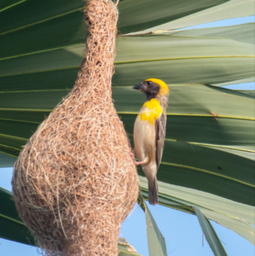

In [4]:
with Image.open(IMAGE_PATH) as source:
    # Composite transparency onto white, if present.
    rgba = source.convert("RGBA")
    image = Image.new("RGBA", rgba.size, "white")
    image.alpha_composite(rgba)
    image = image.convert("RGB")

image.thumbnail((MAX_SIDE, MAX_SIDE), Image.Resampling.LANCZOS)
width, height = image.size
print(f"Training image: {width} × {height} = {width * height:,} pixels")

display(image)

In [5]:
pixels = np.asarray(image, dtype=np.float32) / 255.0

ys = torch.linspace(-1, 1, height)
xs = torch.linspace(-1, 1, width)
grid_y, grid_x = torch.meshgrid(ys, xs, indexing="ij")

coordinates = torch.stack(
    [grid_x, grid_y], dim=-1
).reshape(-1, 2).to(device)

targets = torch.from_numpy(pixels.copy()).reshape(-1, 3).to(device)

**#MODELS**

In [6]:
class ImageMLP(nn.Module):
    def __init__(self, use_fourier=False, width=128, frequencies=64):
        super().__init__()
        self.use_fourier = use_fourier

        if use_fourier:
            self.register_buffer(
                "B", torch.randn(2, frequencies) * FOURIER_SCALE
            )
            input_dim = frequencies * 2
        else:
            input_dim = 2

        layers = []
        for _ in range(4):
            layers.extend([nn.Linear(input_dim, width), nn.ReLU()])
            input_dim = width

        layers.extend([nn.Linear(width, 3), nn.Sigmoid()])
        self.network = nn.Sequential(*layers)

    def forward(self, xy):
        if self.use_fourier:
            angles = 2 * torch.pi * (xy @ self.B)
            xy = torch.cat([torch.sin(angles), torch.cos(angles)], dim=-1)
        return self.network(xy)

In [7]:
torch.manual_seed(SEED)
plain = ImageMLP(use_fourier=False).to(device)

torch.manual_seed(SEED)
fourier = ImageMLP(use_fourier=True).to(device)

models = {"Plain ReLU": plain, "Fourier + ReLU": fourier}
optimizers = {
    name: torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    for name, model in models.items()
}

for name, model in models.items():
    count = sum(p.numel() for p in model.parameters())
    print(f"{name}: {count:,} trainable parameters")

Plain ReLU: 50,307 trainable parameters
Fourier + ReLU: 66,435 trainable parameters


**#RECONSTRUCTION**

In [8]:
@torch.no_grad()
def reconstruct(model):
    model.eval()
    predictions = torch.cat([
        model(chunk)
        for chunk in coordinates.split(16384)
    ])
    mse = ((predictions - targets) ** 2).mean().item()
    psnr = -10 * np.log10(max(mse, 1e-12))

    array = predictions.reshape(height, width, 3).cpu().numpy()
    model.train()
    return array, psnr


history = {
    name: {"steps": [], "psnr": []}
    for name in models
}
frames = []

# Build GIF frames directly with Pillow.
PANEL_WIDTH = 320
PANEL_HEIGHT = max(1, round(height * PANEL_WIDTH / width))
HEADER_HEIGHT = 55

def record_snapshot(step):
    canvas = Image.new(
        "RGB",
        (PANEL_WIDTH * 3, PANEL_HEIGHT + HEADER_HEIGHT),
        "white",
    )
    draw = ImageDraw.Draw(canvas)

    panels = [("Original", image)]
    scores = []

    for name, model in models.items():
        prediction, psnr = reconstruct(model)
        history[name]["steps"].append(step)
        history[name]["psnr"].append(psnr)
        scores.append(f"{name}: {psnr:.2f} dB")

        predicted_image = Image.fromarray(
            (prediction.clip(0, 1) * 255).round().astype(np.uint8)
        )
        panels.append((f"{name} | {psnr:.2f} dB", predicted_image))

    for index, (title, panel) in enumerate(panels):
        x = index * PANEL_WIDTH
        draw.text((x + 10, 8), title, fill="black")
        draw.text((x + 10, 28), f"Step {step}", fill="black")
        canvas.paste(
            panel.resize(
                (PANEL_WIDTH, PANEL_HEIGHT),
                Image.Resampling.NEAREST,
            ),
            (x, HEADER_HEIGHT),
        )

    frames.append(canvas)
    return " | ".join(scores)

**#TRAIN**

In [11]:
print("\nInitial:", record_snapshot(0))
start = time.perf_counter()

for step in range(1, STEPS + 1):
    indices = torch.randint(
        coordinates.shape[0],
        (min(BATCH_SIZE, coordinates.shape[0]),),
        device=device,
    )
    batch_xy = coordinates[indices]
    batch_rgb = targets[indices]

    for name, model in models.items():
        optimizer = optimizers[name]
        optimizer.zero_grad(set_to_none=True)

        prediction = model(batch_xy)
        loss = nn.functional.mse_loss(prediction, batch_rgb)

        loss.backward()
        optimizer.step()

    if step % SNAPSHOT_EVERY == 0 or step == STEPS:
        scores = record_snapshot(step)
        print(f"Step {step:4d}/{STEPS} | {scores}")

if device.type == "cuda":
    torch.cuda.synchronize()

print(f"\nTotal experiment time: {time.perf_counter() - start:.1f} seconds")



Initial: Plain ReLU: 12.14 dB | Fourier + ReLU: 12.16 dB
Step  100/3000 | Plain ReLU: 16.91 dB | Fourier + ReLU: 21.36 dB
Step  200/3000 | Plain ReLU: 18.10 dB | Fourier + ReLU: 23.87 dB
Step  300/3000 | Plain ReLU: 18.71 dB | Fourier + ReLU: 25.07 dB
Step  400/3000 | Plain ReLU: 19.19 dB | Fourier + ReLU: 25.87 dB
Step  500/3000 | Plain ReLU: 19.49 dB | Fourier + ReLU: 26.52 dB
Step  600/3000 | Plain ReLU: 19.88 dB | Fourier + ReLU: 27.19 dB
Step  700/3000 | Plain ReLU: 20.15 dB | Fourier + ReLU: 27.37 dB
Step  800/3000 | Plain ReLU: 20.20 dB | Fourier + ReLU: 27.27 dB
Step  900/3000 | Plain ReLU: 20.46 dB | Fourier + ReLU: 28.37 dB
Step 1000/3000 | Plain ReLU: 20.51 dB | Fourier + ReLU: 28.51 dB
Step 1100/3000 | Plain ReLU: 20.94 dB | Fourier + ReLU: 28.22 dB
Step 1200/3000 | Plain ReLU: 21.01 dB | Fourier + ReLU: 29.02 dB
Step 1300/3000 | Plain ReLU: 20.71 dB | Fourier + ReLU: 29.12 dB
Step 1400/3000 | Plain ReLU: 21.31 dB | Fourier + ReLU: 29.37 dB
Step 1500/3000 | Plain ReLU: 21.

**#SAVE IMAGES**

In [12]:
image.save(OUTPUT_DIR / "reference.png")

for name, model in models.items():
    slug = "plain_relu" if name == "Plain ReLU" else "fourier_relu"
    prediction, _ = reconstruct(model)

    Image.fromarray(
        (prediction.clip(0, 1) * 255).round().astype(np.uint8)
    ).save(OUTPUT_DIR / f"{slug}.png")

    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizers[name].state_dict(),
        "step": STEPS,
        "image_size": (width, height),
        "use_fourier": name == "Fourier + ReLU",
        "hidden_width": 128,
        "hidden_layers": 4,
        "frequencies": 64,
        "fourier_scale": FOURIER_SCALE,
        "coordinate_range": (-1, 1),
        "seed": SEED,
    }, OUTPUT_DIR / f"{slug}.pt")

gif_path = OUTPUT_DIR / "training_comparison.gif"
frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=[250] * (len(frames) - 1) + [2000],
    loop=0,
)

frames[-1].save(OUTPUT_DIR / "final_comparison.png")

**#PLOT**

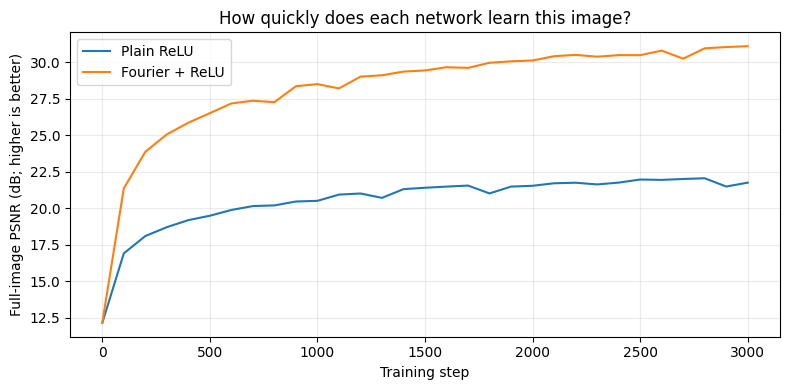

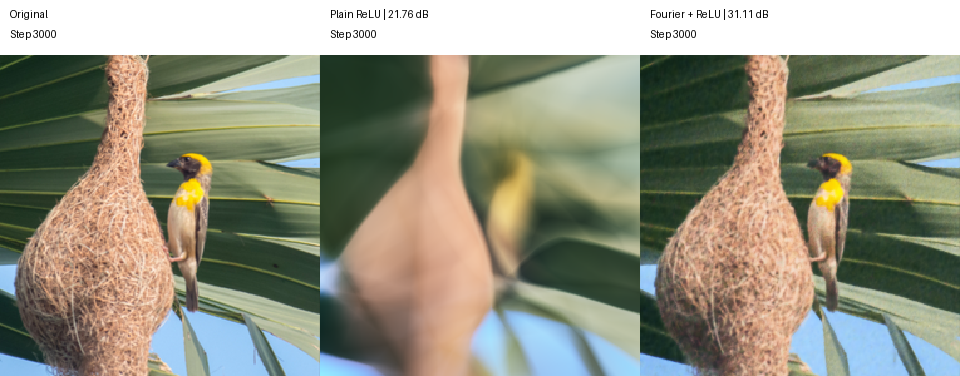

/kaggle/working/bird_experiment/training_comparison.gif

/kaggle/working/bird_experiment/final_comparison.png

In [13]:
plt.figure(figsize=(8, 4))
for name, values in history.items():
    plt.plot(values["steps"], values["psnr"], label=name)

plt.xlabel("Training step")
plt.ylabel("Full-image PSNR (dB; higher is better)")
plt.title("How quickly does each network learn this image?")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curve.png", dpi=150)
plt.show()

display(frames[-1])
display(FileLink(str(gif_path)))
display(FileLink(str(OUTPUT_DIR / "final_comparison.png")))